In [64]:
import xarray as xr
import pandas as pd

In [65]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import numpy as np
import re
import os

# =========================================================
# === 1. CONFIGURACIÓN BASE DEL MAPA
# =========================================================
def setup_map(ax, proj_map, proj_data):
    """Configura el mapa base en un eje Cartopy."""
    ax.coastlines(resolution='110m')
    ax.add_feature(cfeature.BORDERS, linestyle=':')
    ax.add_feature(cfeature.LAND, facecolor='lightgray')


# =========================================================
# === 2. PLOT T2M + Z500
# =========================================================
def plot_temp_z500(ax, lon, lat, temp_field, z500_field,
                   levels_temp, levels_z500,
                   proj_data):

    # --- Temperature filled contours ---
    temp_plot = ax.contourf(
        lon, lat, temp_field,
        levels=levels_temp,
        cmap='bwr',
        extend='both',
        transform=proj_data
    )

    # --- Z500 gray contour lines ---
    c = ax.contour(
        lon, lat, z500_field,
        levels=levels_z500,
        colors='gray',
        linewidths=1.0,
        transform=proj_data
    )

    ax.clabel(
        c,
        fmt='%d',
        fontsize=7,
        colors='gray'
    )

    return temp_plot

# =========================================================
# === 3. PLOT PRECIPITACIÓN
# =========================================================
def plot_precip(ax, lon, lat, precip_field,
                levels_precip, cmap_precip,
                proj_data):

    precip_plot = ax.contourf(
        lon,
        lat,
        precip_field,
        levels=levels_precip,
        cmap=cmap_precip,
        extend='max',
        transform=proj_data
    )

    return precip_plot

def plot_shapefile_mask(ax, lon, lat, mask, color='magenta', lw=2, proj_data=ccrs.PlateCarree()):
    """Plotea un shapefile o mascarilla como contorno."""
    ax.contour(lon, lat, mask, levels=[0.5], colors=color,
               linewidths=lw, transform=proj_data)

# === Normalización de contraste ===
def normalize(band):
    band_min, band_max = np.nanpercentile(band, (2, 98))
    return np.clip((band - band_min) / (band_max - band_min), 0, 1)

import rasterio
from rasterio.windows import from_bounds
from pyproj import Transformer

# === Función para leer GeoTIFF recortado ===
def read_rgb_tiff_crop(tif_path, crop_extent):
    with rasterio.open(tif_path) as src:
        crs = src.crs
        transformer = Transformer.from_crs("EPSG:4326", crs, always_xy=True)
        left, bottom = transformer.transform(crop_extent[0], crop_extent[2])
        right, top = transformer.transform(crop_extent[1], crop_extent[3])

        window = from_bounds(left, bottom, right, top, src.transform)

        r = src.read(1, window=window).astype(float)
        g = src.read(2, window=window).astype(float)
        b = src.read(3, window=window).astype(float)

        transform = src.window_transform(window)
        lon_min, lat_min = crop_extent[0], crop_extent[2]
        lon_max, lat_max = crop_extent[1], crop_extent[3]

    # Normalizar
    r_norm, g_norm, b_norm = normalize(r), normalize(g), normalize(b)
    rgb = np.dstack((r_norm, g_norm, b_norm))

    filename = os.path.basename(tif_path)
    match = re.search(r"(\d{4}-\d{2}-\d{2})", filename)
    fecha = match.group(1) if match else "Fecha desconocida"

    extent = [lon_min, lon_max, lat_min, lat_max]
    return rgb, extent, fecha

# =========================================================
# === 3. PLOT IVT (magnitud + vectores)
# =========================================================
def plot_ivt(ax, lon, lat, ivt_mag, ivt_u, ivt_v,
             proj_data, norm, bounds, cmap):

    # --- Magnitud IVT ---
    ivt_plot = ax.contourf(
        lon.values, lat.values, ivt_mag.values,
        levels=bounds, cmap=cmap, norm=norm, extend="max",
        transform=proj_data
    )

    # --- Vectores (thinned) ---
    skip = 5

    Q = ax.quiver(
        lon.values[::skip],
        lat.values[::skip],
        ivt_u.values[::skip, ::skip],
        ivt_v.values[::skip, ::skip],
        transform=proj_data,
        scale=7500, width=0.002, color='k', regrid_shape=40
    )

    ax.quiverkey(Q, 0.92, 1.01, 300, "500", labelpos='E')

    return ivt_plot


In [66]:
from matplotlib.colors import ListedColormap

colors = [
    "#f0f0f0",
    "#7ea6ff",
    "#3366ff",
    "#1e90ff",
    "#00c5cd",
    "#00c878",
    "#32cd32",
    "#9acd32",
    "#ffd54f",
    "#ffb347",
    "#ff7f50",
    "#ff4500",
    "#ff1493",
    "#c050ff",
    "#6a3d9a"
]

cmap_precip = ListedColormap(colors)


In [67]:
filename = '~/ERA5/IVTu_12UTC_75.nc'
IVTu = xr.open_dataset(filename)

filename = '~/ERA5/IVTv_12UTC_75.nc'
IVTv = xr.open_dataset(filename)

IVT = np.sqrt(IVTu.viwve_12UTC**2 + IVTv.viwvn_12UTC**2)
IVT_masked = IVT.where(IVT >= 250)


In [68]:
filename = '/home/cr2/cmtorres/ARs_DATA/Global_AR_dataset_Guan.nc'
AR_shape = xr.open_dataset(filename).sel(time=slice('1980-01-01', '2022-12-31'), ens = 1, lev = 0)
AR_shape.coords['lon'] = (AR_shape.coords['lon'] + 180) % 360 - 180
AR_shape = AR_shape.sortby(AR_shape.lon)


In [69]:
filename = '/home/cr2/cmtorres/ARs_DATA/AR_Buffet_1979_2023.nc'
AR_shape_B = xr.open_dataset(filename)
AR_shape_B.coords['lon'] = (AR_shape_B.coords['lon'] + 180) % 360 - 180
AR_shape_B = AR_shape_B.sortby(AR_shape_B.lon)

In [70]:
IVTv

<xarray.Dataset> Size: 2GB
Dimensions:      (time: 6806, latitude: 134, longitude: 480)
Coordinates:
    number       int64 8B ...
  * time         (time) datetime64[ns] 54kB 1979-01-01T12:00:00 ... 2023-12-3...
  * latitude     (latitude) float64 1kB 9.75 9.0 8.25 7.5 ... -88.5 -89.25 -90.0
  * longitude    (longitude) float64 4kB -180.0 -179.2 -178.5 ... 178.5 179.2
    expver       (time) <U4 109kB ...
Data variables:
    viwvn_12UTC  (time, latitude, longitude) float32 2GB -49.45 ... -2.912

Saved: ./fig/map_IVT_2022-02-07.png


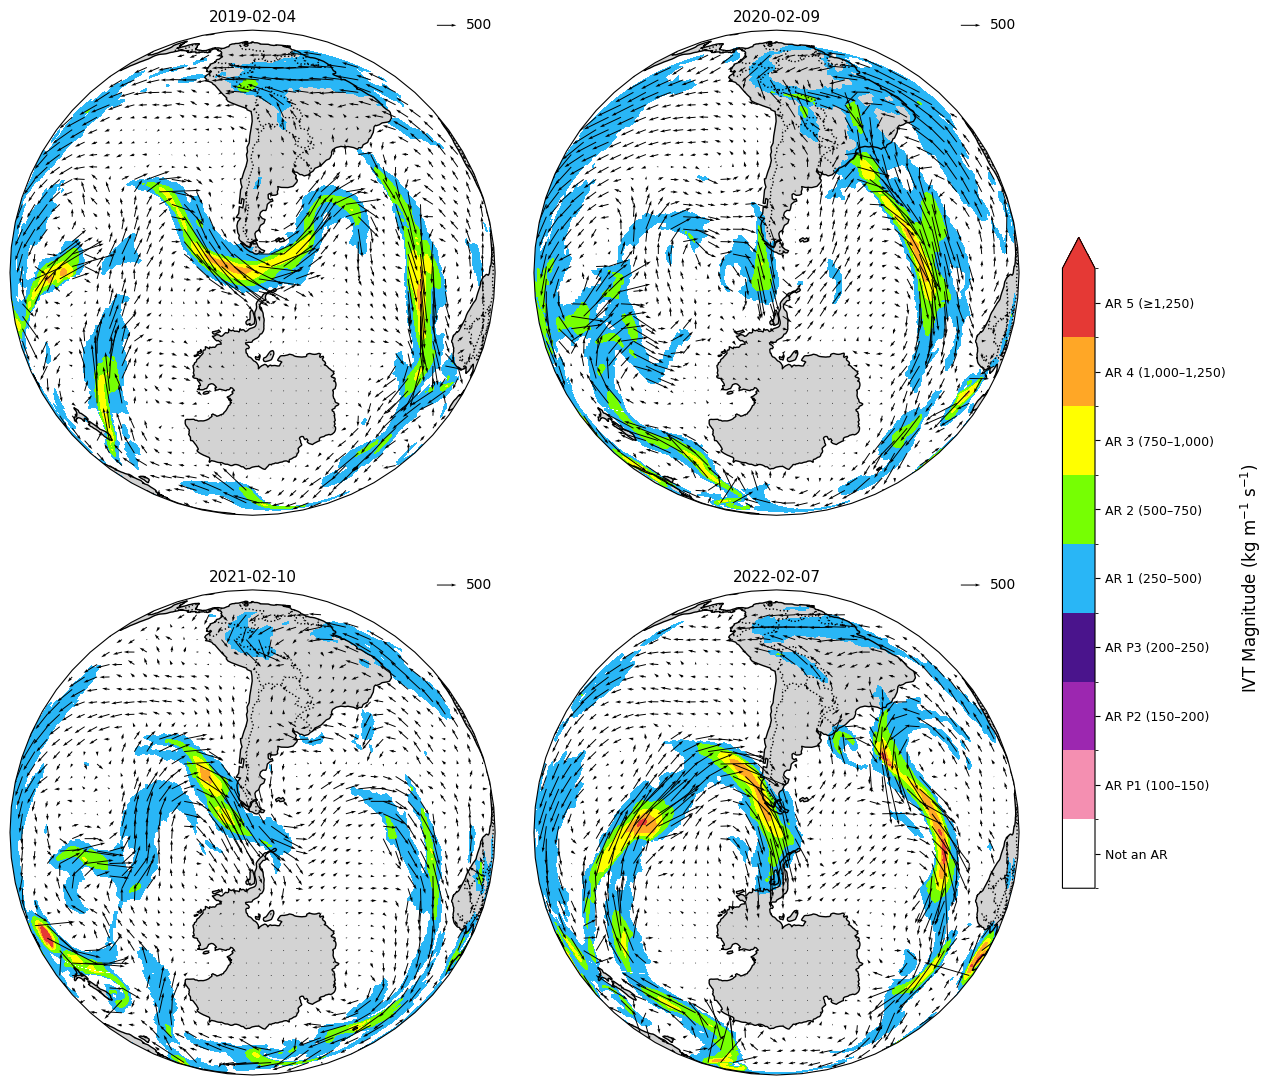

In [73]:
import os
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import xarray as xr
import cartopy.crs as ccrs

# Output directory for saving images
output_dir = "./fig"
os.makedirs(output_dir, exist_ok=True)

# -------------------------------------------------------------------------
# Extended AR Scale for Polar Regions Configuration
# -------------------------------------------------------------------------
bounds = [0, 100, 150, 200, 250, 500, 750, 1000, 1250, 1500]

# Hex colors corresponding to the Extended Polar AR Scale
colors = [
    (0, 0, 0, 0),      # Below 100: Not an AR (Transparent)
    "#F48FB1",         # 100-150: AR P1 (Pink)
    "#9C27B0",         # 150-200: AR P2 (Medium Purple)
    "#4A148C",         # 200-250: AR P3 (Dark Purple)
    "#29B6F6",         # 250-500: AR 1  (Light Blue)
    "#76FF03",         # 500-750: AR 2  (Lime Green)
    "#FFFF00",         # 750-1000: AR 3 (Yellow)
    "#FFA726",         # 1000-1250: AR 4 (Orange)
    "#E53935",         # 1250+: AR 5   (Red)
]

# Pass extend='max' to the colormap instead of BoundaryNorm
cmap = mcolors.ListedColormap(colors).with_extremes(over="#E53935")
norm = mcolors.BoundaryNorm(bounds, cmap.N)

# -------------------------------------------------------------------------
# Figure Setup
# -------------------------------------------------------------------------
lon, lat = IVTu.longitude, IVTu.latitude

proj_map = ccrs.Orthographic(-70, -60)
proj_data = ccrs.PlateCarree()

fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 14),
    subplot_kw={"projection": proj_map},
    gridspec_kw={"wspace": 0.08, "hspace": 0.08},
)

dates = ["2019-02-04", "2020-02-09", "2021-02-10", "2022-02-07"]
mslp_handles = []

# Loop through subplots and plot IVT
for ax, date_str in zip(axes.flat, dates):
    setup_map(ax, proj_map, proj_data)

    h = plot_ivt(
        ax,
        lon,
        lat,
        IVT_masked.sel(time=date_str)[0],
        IVTu.viwve_12UTC.sel(time=date_str)[0],
        IVTv.viwvn_12UTC.sel(time=date_str)[0],
        proj_data,
        norm,
        bounds,
        cmap,
    )

    ax.set_title(f"{date_str}", fontsize=11)
    mslp_handles.append(h)

# -------------------------------------------------------------------------
# Global Colorbar using plt.colorbar()
# -------------------------------------------------------------------------
# Midpoints of the boundaries for center-aligned tick positions
tick_positions = [50, 125, 175, 225, 375, 625, 875, 1125, 1375]
tick_labels = [
    "Not an AR",
    "AR P1 (100–150)",
    "AR P2 (150–200)",
    "AR P3 (200–250)",
    "AR 1 (250–500)",
    "AR 2 (500–750)",
    "AR 3 (750–1,000)",
    "AR 4 (1,000–1,250)",
    "AR 5 (≥1,250)",
]

cbar = plt.colorbar(
    mslp_handles[0],
    ax=axes,
    orientation="vertical",
    fraction=0.03,
    pad=0.04,
    ticks=tick_positions,
)

# Use set_yticklabels for vertical orientation
cbar.ax.set_yticklabels(
    tick_labels,
    fontsize=9,
    ha="left",  # Aligns text neatly next to the colorbar ticks
)

cbar.set_label(r"IVT Magnitude (kg m$^{-1}$ s$^{-1}$)", fontsize=12, labelpad=10)

# Save figure and release memory
save_path = os.path.join(output_dir, f"map_IVT_{date_str}.png")
print(f"Saved: {save_path}")
plt.savefig(save_path, dpi=200, bbox_inches="tight")
#plt.close(fig)


